# Pêndulo: novas figuras 3 e 5

Notebook independente: contém todo o código, não depende de importar o arquivo `.py`.

Modelo: $\ddot\theta+q\dot\theta+\sin\theta=f\cos(\Omega t)$, com $\Omega=2/3$ e tempo adimensional. Amostramos sempre na fase zero do forçamento.

As figuras são exibidas nos resultados salvos deste notebook. **Executar todas as células novamente calcula tudo do início quando não há arquivos de dados na pasta.** Pode levar vários minutos e grava aproximadamente 70–100 MB de resultados locais. Para uma execução curta, reduza `N_FRACTAL`, sabendo que isso piora a convergência da dimensão.

Dependências: `numpy`, `scipy`, `matplotlib`, `numba`. Se necessário, execute em uma célula: `%pip install numpy scipy matplotlib numba`.

Os painéis densos são obtidos pela redução da dissipação, explicitamente indicada em cada painel. Não foram misturados transientes nem adicionado ruído para preencher os gráficos.

In [1]:
"""Poincare sections, checked invariant manifolds and fractal convergence.

All times and velocities are dimensionless. Phase zero means cos(Omega*t)=1.
Can be imported into Jupyter. Nothing expensive runs on import.
"""
from pathlib import Path
import json
import math
import numpy as np
import matplotlib.pyplot as plt
from numba import njit
from scipy.integrate import solve_ivp,solve_bvp
from scipy.optimize import root, least_squares
from scipy.spatial import cKDTree

OMEGA=2/3
OUT=Path.cwd()

def wrap(theta):
    return (np.asarray(theta)+np.pi)%(2*np.pi)-np.pi

@njit
def _rhs(th,w,u,v,c,q,f):
    return w,-math.sin(th)-q*w+f*c,v,-math.cos(th)*u-q*v

@njit
def sample(q=.5,f=1.2,omega=2/3,steps=480,burn=4000,keep=65536,theta0=.2,vel0=0.):
    """RK4 state + same-phase tangent. Renormalize each period, discard burn."""
    T=2*np.pi/omega; h=T/steps
    th=theta0;w=vel0;u=1.;v=0.
    cs=np.cos(2*np.pi*np.arange(steps)/steps)
    cm=np.cos(2*np.pi*(np.arange(steps)+.5)/steps)
    ce=np.cos(2*np.pi*(np.arange(steps)+1)/steps)
    points=np.empty((keep,2));growth=np.empty(keep)
    for n in range(burn+keep):
        for j in range(steps):
            a,b,c,d=_rhs(th,w,u,v,cs[j],q,f)
            e,g,k,l=_rhs(th+h*a/2,w+h*b/2,u+h*c/2,v+h*d/2,cm[j],q,f)
            m,o,p,r=_rhs(th+h*e/2,w+h*g/2,u+h*k/2,v+h*l/2,cm[j],q,f)
            s,t,x,y=_rhs(th+h*m,w+h*o,u+h*p,v+h*r,ce[j],q,f)
            th+=h*(a+2*e+2*m+s)/6;w+=h*(b+2*g+2*o+t)/6
            u+=h*(c+2*k+2*p+x)/6;v+=h*(d+2*l+2*r+y)/6
        norm=math.hypot(u,v);u/=norm;v/=norm
        if n>=burn:
            z=n-burn;points[z,0]=(th+np.pi)%(2*np.pi)-np.pi
            points[z,1]=w;growth[z]=math.log(norm)/T
    return points,growth

def flow(x,q,f,omega=OMEGA,periods=1,rtol=2e-12,atol=2e-14,tangent=False):
    """DOP853 signed-period flow; theta remains unwrapped."""
    T=2*np.pi/omega
    if tangent:
        y=np.r_[x,np.eye(2).ravel()]
        def rhs(t,y):
            th,w=y[:2];J=np.array([[0.,1.],[-np.cos(th),-q]])
            return np.r_[w,-np.sin(th)-q*w+f*np.cos(omega*t),(J@y[2:].reshape(2,2)).ravel()]
    else:
        y=np.array(x,dtype=float)
        def rhs(t,y):
            return [y[1],-np.sin(y[0])-q*y[1]+f*np.cos(omega*t)]
    sol=solve_ivp(rhs,[0,periods*T],y,method='DOP853',rtol=rtol,atol=atol)
    if not sol.success:raise RuntimeError(sol.message)
    if tangent:return sol.y[:2,-1],sol.y[2:,-1].reshape(2,2)
    return sol.y[:,-1]

def periodic_saddle(q=.05,f=.12,omega=OMEGA,rtol=2e-12):
    """Locate the nonrotating period-T saddle by periodic BVP and Newton shooting."""
    T=2*np.pi/omega;t=np.linspace(0,T,201)
    a=-f*(1+omega**2)/((1+omega**2)**2+(q*omega)**2)
    b=-q*omega*a/(1+omega**2)
    guess=np.array([np.pi+a*np.cos(omega*t)+b*np.sin(omega*t),
                    -omega*a*np.sin(omega*t)+omega*b*np.cos(omega*t)])
    def rhs(t,y):return np.array([y[1],-np.sin(y[0])-q*y[1]+f*np.cos(omega*t)])
    bvp=solve_bvp(rhs,lambda ya,yb:ya-yb,t,guess,tol=1e-10,max_nodes=10000)
    if not bvp.success:raise RuntimeError(bvp.message)
    def fun(y):
        end,A=flow(y,q,f,omega,rtol=rtol,tangent=True)
        return end-y,A-np.eye(2)
    sol=root(fun,bvp.y[:,0],jac=True,tol=1e-10)
    x=sol.x
    residual=np.linalg.norm(fun(x)[0])
    if residual>1e-7:raise RuntimeError(f'Saddle shooting failed: {residual}')
    end,A=flow(x,q,f,omega,rtol=rtol,tangent=True)
    vals,vec=np.linalg.eig(A);i=np.argmax(abs(vals));j=np.argmin(abs(vals))
    eu=np.real(vec[:,i]);es=np.real(vec[:,j]);eu/=np.linalg.norm(eu);es/=np.linalg.norm(es)
    if eu[0]<0:eu=-eu
    if es[0]<0:es=-es
    assert abs(vals[i])>1 and abs(vals[j])<1
    return {'x':x,'matrix':A,'unstable_multiplier':float(vals[i].real),
            'stable_multiplier':float(vals[j].real),'eu':eu,'es':es,
            'shooting_residual':float(np.linalg.norm(end-x)),
            'determinant_relative_error':float(abs(np.linalg.det(A)/np.exp(-q*2*np.pi/omega)-1))}

def periodic_reference(q=.05,f=.12,omega=OMEGA,tol=2e-12):
    """Periodic BVP reference used to avoid subtractive cancellation near saddle."""
    T=2*np.pi/omega;t=np.linspace(0,T,401)
    a=-f*(1+omega**2)/((1+omega**2)**2+(q*omega)**2)
    b=-q*omega*a/(1+omega**2)
    guess=np.array([np.pi+a*np.cos(omega*t)+b*np.sin(omega*t),
                   -omega*a*np.sin(omega*t)+omega*b*np.cos(omega*t)])
    def rhs(t,y):return np.array([y[1],-np.sin(y[0])-q*y[1]+f*np.cos(omega*t)])
    ref=solve_bvp(rhs,lambda ya,yb:ya-yb,t,guess,tol=tol,max_nodes=20000)
    if not ref.success:raise RuntimeError(ref.message)
    return ref

def deviation_flow(delta,ref,q=.05,omega=OMEGA,periods=2,rtol=2e-12):
    """Integrate displacement from a periodic reference without adding tiny seeds.

    sin(p+d)-sin(p)=2*cos(p+d/2)*sin(d/2) retains small displacements accurately.
    """
    T=2*np.pi/omega;y=np.r_[delta,np.eye(2).ravel()]
    def rhs(t,y):
        thp=float(ref.sol(t%T)[0]);d,w=y[:2]
        J=np.array([[0.,1.],[-np.cos(thp+d),-q]])
        return np.r_[w,-2*np.cos(thp+d/2)*np.sin(d/2)-q*w,
                     (J@y[2:].reshape(2,2)).ravel()]
    sol=solve_ivp(rhs,[0,periods*T],y,method='DOP853',rtol=rtol,
                  atol=np.array([1e-26,1e-26,1e-14,1e-14,1e-14,1e-14]))
    if not sol.success:raise RuntimeError(sol.message)
    return sol.y[:2,-1],sol.y[2:,-1].reshape(2,2)

def crossing_convergence(crossing,saddle,q=.05,f=.12,omega=OMEGA,lengths=(2,3,4),rtol=2e-12):
    """Refine a crossing with longer local legs and independent solver settings.

    Increasing leg length reduces the endpoint seed. Tests local eigenline
    truncation as well as integration accuracy; not just denser plotted points.
    """
    ref=periodic_reference(q,f,omega);previous=np.array(crossing['parameters'])
    last_length=2;results=[]
    for length in lengths:
        change=length-last_length
        start=previous*np.array([saddle['unstable_multiplier']**(-change),
                                 saddle['stable_multiplier']**change])
        def evaluate(z):
            su,ss=np.exp(z)
            pu,Au=deviation_flow(crossing['sign_u']*su*saddle['eu'],ref,q,omega,length,rtol)
            ps,As=deviation_flow(crossing['sign_s']*ss*saddle['es'],ref,q,omega,-length,rtol)
            vu=Au@(crossing['sign_u']*saddle['eu']);vs=As@(crossing['sign_s']*saddle['es'])
            residual=pu-ps-np.array([crossing['shift']*2*np.pi,0.])
            J=np.column_stack((su*vu,-ss*vs))
            return residual,J,pu,vu,vs
        sol=root(lambda z:evaluate(z)[:2],np.log(start),jac=True,tol=1e-10)
        residual,J,pu,vu,vs=evaluate(sol.x)
        cos=abs(np.dot(vu,vs)/(np.linalg.norm(vu)*np.linalg.norm(vs)))
        point=ref.y[:,0]+pu;point[0]=wrap(point[0])
        results.append({'length':length,'point':point,'parameters':np.exp(sol.x),
                        'residual':float(np.linalg.norm(residual)),
                        'angle_deg':float(np.degrees(np.arccos(np.clip(cos,0,1)))),
                        'tangent_u':vu/np.linalg.norm(vu),'tangent_s':vs/np.linalg.norm(vs),
                        'rtol':rtol,'root_success':bool(sol.success)})
        previous=np.exp(sol.x);last_length=length
    return results

CASES=(.9,1.07,1.08,1.085,1.16,1.2)

def figure3(directory=OUT,force=False,n=65536,fixed_damping=False):
    """Six asymptotic sections; finite periodic sets are never filled artificially."""
    directory=Path(directory);report=[]
    plt.rcParams.update({'font.size':10,'axes.titlesize':11,'pdf.fonttype':42})
    fig,axes=plt.subplots(2,3,figsize=(11.3,7.1),sharex=True,sharey=True)
    cases=[(.5,f) for f in CASES] if fixed_damping else [(.5,.9),(.5,1.07),(.5,1.2),(.2,.8),(.1,1.2),(.05,.6)]
    periods=[1,2,3,None,None,None] if fixed_damping else [1,2,None,None,None,None]
    labels=['Period 1','Period 2','Period 3','Narrow chaotic bands','Chaotic attractor','Chaotic attractor'] if fixed_damping else ['Period 1','Period 2','Filamentary chaos','Broader chaotic attractor','Broader chaotic attractor','Weak-damping chaos']
    for i,(ax,(q,f),label,period) in enumerate(zip(axes.flat,cases,labels,periods)):
        path=directory/(f'gallery_f{f:.4f}.npz' if q==.5 else f'gallery_q{q:.3f}_f{f:.4f}.npz')
        if path.exists() and not force:
            d=np.load(path);p,g=d['points'],d['growth']
        else:
            p,g=sample(q=q,f=f,steps=480,burn=8000,keep=n)
            np.savez_compressed(path,points=p,growth=g)
        col='#164d7a' if period else '#a81d33'
        if period:
            psmall=np.unique(np.round(p,7),axis=0)
            ax.scatter(psmall[:,0],psmall[:,1],s=38,color=col,zorder=3)
        else:
            ax.scatter(p[:,0],p[:,1],s=.14,color=col,rasterized=True,linewidths=0)
        ax.set_title(fr'({chr(97+i)}) $q={q:g}$, $f={f:g}$'+'\n'+label)
        blocks=np.array([b.mean() for b in np.array_split(g,8)])
        ax.text(.04,.04,fr'$\lambda_{{\max}}={g.mean():+.4f}$',transform=ax.transAxes,
                fontsize=10,bbox=dict(facecolor='white',edgecolor='none',alpha=.88,pad=2))
        ax.set_xticks([-np.pi,-np.pi/2,0,np.pi/2,np.pi],
                      [r'$-\pi$',r'$-\pi/2$','0',r'$\pi/2$',r'$\pi$'])
        ax.set(xlim=(-np.pi,np.pi),ylim=(-.65,2.5) if fixed_damping else (-2.4,3.1))
        if i%3==0:ax.set_ylabel(r'$\omega$')
        if i>=3:ax.set_xlabel(r'$\bar\theta$')
        ax.grid(alpha=.12,lw=.4)
        report.append({'f':f,'q':q,'omega':OMEGA,'lambda':float(g.mean()),
                       'block_range':[float(blocks.min()),float(blocks.max())],
                       'period':period,'points':len(p)})
    fig.suptitle(r'Stroboscopic sections: $\Omega=2/3$, drive phase $0$',y=.995)
    name='figura_3_amplitudes_q_fixo' if fixed_damping else 'figura_3_seis_regimes'
    fig.tight_layout(rect=(0,0,1,.96));save(fig,name,directory)
    (directory/(name+'_resultados.json')).write_text(json.dumps(report,indent=2))
    return fig,report

def compute_manifolds(directory=OUT,force=False):
    directory=Path(directory)
    checked=directory/'crossing_checks.json';curvesfile=directory/'manifold_curves.npz'
    if checked.exists() and curvesfile.exists() and not force:
        return np.load(curvesfile),json.loads(checked.read_text())
    saddle=periodic_saddle();allcurves={};objects={}
    for kind in ['u','s']:
        for sign in [-1,1]:
            c=manifold_curve(saddle,kind,sign)
            objects[kind+str(sign)]=c
            for key in ['points','s']:allcurves[kind+str(sign)+'_'+key]=c[key]
    np.savez_compressed(curvesfile,**allcurves)
    results=[];u=objects['u1'];s=objects['s1']
    for guess in segment_candidates(u,s):
        cr=refine_crossing(guess,u,s,saddle)
        if .7<cr['point'][1]<1.3 and 1.7<cr['point'][0]<2.2:
            checks=crossing_convergence(cr,saddle)
            tight=crossing_convergence(cr,saddle,lengths=(3,),rtol=2e-13)
            if any(row['residual']>1e-8 for row in checks+tight):
                raise RuntimeError('Crossing matching residual failed the validation threshold')
            if max(np.linalg.norm(np.array(row['point'])-checks[-1]['point']) for row in checks)>1e-6:
                raise RuntimeError('Crossing failed endpoint-length convergence')
            if any(row['angle_deg']<.01 for row in checks+tight):
                raise RuntimeError('Transversality is unresolved at the selected precision')
            results.append({'initial':cr,'length_checks':checks,'tight_checks':tight})
    if len(results)!=2:raise RuntimeError('Expected two independently resolved crossings in the selected zoom')
    checked.write_text(json.dumps(results,default=to_json,indent=2))
    (directory/'saddle_results.json').write_text(json.dumps(saddle,default=to_json,indent=2))
    return np.load(curvesfile),results

def compute_fractal(directory=OUT,force=False,n=2097152):
    """Large sample, 16 grid origins, all windows, matched-length step refinement."""
    directory=Path(directory);path=directory/'fractal_long_2m.npz'
    if path.exists() and not force:
        with np.load(path) as old:
            if len(old['points'])!=n:force=True
    if not path.exists() or force:
        p,g=sample(f=1.2,steps=480,burn=4000,keep=n)
        np.savez_compressed(path,points=p,growth=g)
    data=np.load(path);p,g=data['points'],data['growth']
    statsfile=directory/'fractal_stats_2m.npz'
    if not statsfile.exists() or force:
        st=cell_statistics(p,levels=range(3,15));win=window_slopes(st)
        np.savez_compressed(statsfile,**st,**{'fit_'+k:v for k,v in win.items()})
    refinementfile=directory/'fractal_refined.npz'
    if not refinementfile.exists() or force:
        pr,gr=sample(f=1.2,steps=960,burn=8000,keep=min(524288,n))
        np.savez_compressed(refinementfile,points=pr,growth=gr)
    ns=[16384,65536,262144,524288,1048576,len(p)]
    ns=sorted(set(k for k in ns if k<=len(p)))
    samplefile=directory/'sample_convergence.npz'
    if not samplefile.exists() or force:
        rows=[];info=[]
        for k in ns:
            st=cell_statistics(p[:k],levels=range(6,11))
            rows.append(np.polyfit(st['x'],np.log(st['counts']).T,1)[0])
            info.append(np.polyfit(st['x'],st['entropy'].T,1)[0])
        np.savez_compressed(samplefile,n=ns,D0=rows,D1=info)
    return data,np.load(statsfile),np.load(samplefile),np.load(refinementfile)

def _plot_curve(ax,points,color,label=None,lw=.7):
    p=points.copy();p[:,0]=wrap(p[:,0])
    jumps=np.flatnonzero(abs(np.diff(p[:,0]))>np.pi)+1
    pieces=np.split(p,jumps)
    for j,part in enumerate(pieces):
        ax.plot(part[:,0],part[:,1],color=color,lw=lw,label=label if j==0 else None)

def figure5(directory=OUT,force=False,n=2097152):
    """Two different parameter regimes explicitly separated within six panels."""
    directory=Path(directory);curves,crossings=compute_manifolds(directory,force)
    data,stats,conv,refined=compute_fractal(directory,force,n=n)
    p=data['points'];g=data['growth'];levels=stats['levels'];x=stats['x']
    ky=1+g.mean()/(.5+g.mean());sel=(levels>=6)&(levels<=10)
    d0=np.polyfit(x[sel],np.log(stats['counts'][:,sel]).T,1)[0]
    d1=np.polyfit(x[sel],stats['entropy'][:,sel].T,1)[0]
    fig,axs=plt.subplots(3,2,figsize=(10.7,11.5))
    for kind,col,label in [('u','#ae2139',r'$W^u$'),('s','#166aa5',r'$W^s$')]:
        for sign in [-1,1]:
            _plot_curve(axs[0,0],curves[kind+str(sign)+'_points'],col,label if sign==1 else None)
        _plot_curve(axs[0,1],curves[kind+'1_points'],col,lw=1.0)
    for i,item in enumerate(crossings):
        cr=item['length_checks'][-1];pt=cr['point']
        for ax in axs[0]:ax.plot(*pt,'o',ms=4,color='black',zorder=5)
        axs[0,1].annotate(fr'$C_{i+1}$: {cr["angle_deg"]:.2f}$^\circ$',pt,
                         xytext=(pt[0]+.012,pt[1]+.055),fontsize=9,
                         arrowprops=dict(arrowstyle='-',lw=.6))
    saddle=periodic_saddle()
    axs[0,0].plot(float(wrap(saddle['x'][0])),saddle['x'][1],'D',color='black',ms=4,label='Periodic saddle')
    axs[0,0].set(xlim=(-np.pi,np.pi),ylim=(-2.7,2.7),xlabel=r'$\bar\theta$',ylabel=r'$\omega$',
                 title=r'(a) Manifolds: $q=0.05$, $f=0.12$')
    axs[0,0].legend(loc='lower center',ncol=3,fontsize=8)
    axs[0,1].set(xlim=(1.78,2.14),ylim=(.78,1.17),xlabel=r'$\bar\theta$',ylabel=r'$\omega$',
                 title='(b) Crossings confirmed by direct shooting')
    from matplotlib.patches import Rectangle
    axs[0,0].add_patch(Rectangle((1.78,.78),.36,.39,fill=False,ec='black',lw=.8))
    display=p[::max(1,len(p)//400000)]
    axs[1,0].scatter(display[:,0],display[:,1],s=.04,c='#ae2139',linewidths=0,rasterized=True)
    axs[1,0].add_patch(Rectangle((1.7,-.17),.45,.25,fill=False,ec='#164d7a',lw=.9))
    axs[1,0].set(xlim=(-np.pi,np.pi),ylim=(-.55,2.4),xlabel=r'$\bar\theta$',ylabel=r'$\omega$',
                 title=r'(c) Attractor: $q=0.5$, $f=1.2$')
    mask=(p[:,0]>1.7)&(p[:,0]<2.15)&(p[:,1]>-.17)&(p[:,1]<.08)
    pp=p[mask][::4]
    axs[1,1].scatter(pp[:,0],pp[:,1],s=.08,c='#ae2139',linewidths=0,rasterized=True)
    axs[1,1].set(xlim=(1.7,2.15),ylim=(-.17,.08),xlabel=r'$\bar\theta$',ylabel=r'$\omega$',title='(d) Resolved filaments: magnified region')
    # Grid-origin envelopes, rather than one fortunate lattice origin.
    logcnt=np.log(stats['counts']);mean=logcnt.mean(axis=0)
    axs[2,0].fill_between(x,logcnt.min(axis=0),logcnt.max(axis=0),alpha=.18,color='#164d7a',label='16 grid origins')
    axs[2,0].plot(x,mean,'o-',ms=3,color='#164d7a',lw=1)
    fit=np.polyfit(x[sel],mean[sel],1)
    axs[2,0].plot(x[sel],np.polyval(fit,x[sel]),'--',color='#ae2139',lw=1.2,label=fr'five-scale slope {fit[0]:.3f}')
    axs[2,0].axvspan(x[sel][0],x[sel][-1],color='#b98529',alpha=.12)
    axs[2,0].set(xlabel=r'$\ln(1/\delta)$',ylabel=r'$\ln N_{\rm box}(\delta)$',title='(e) Box counting with grid-origin envelope')
    axs[2,0].legend(fontsize=8)
    for key,col,label in [('D0','#164d7a',r'$\widehat D_0$'),('D1','#ae2139',r'$\widehat D_1$')]:
        yy=conv[key]
        axs[2,1].fill_between(conv['n'],yy.min(axis=1),yy.max(axis=1),alpha=.15,color=col)
        axs[2,1].plot(conv['n'],np.median(yy,axis=1),'o-',ms=3,color=col,label=label)
    axs[2,1].axhline(ky,color='.3',ls='--',lw=.9,label=fr'$D_{{\rm KY}}={ky:.3f}$')
    axs[2,1].set_xscale('log',base=2)
    axs[2,1].set(xlabel='Retained stroboscopic points',ylabel='Five-scale fitted dimension',title='(f) Sample-size and grid-origin convergence')
    axs[2,1].legend(fontsize=8,ncol=3)
    for ax in axs.flat:ax.grid(alpha=.12,lw=.4)
    fig.suptitle(r'Invariant-manifold crossings and fractal geometry; $\Omega=2/3$, phase $0$',y=.999)
    fig.tight_layout(rect=(0,0,1,.985),h_pad=2.1);save(fig,'figura_5_cruzamentos_e_fractal',directory)
    report={'N':len(p),'lambda':float(g.mean()),'KY':float(ky),'fit_levels':[6,7,8,9,10],
            'D0_median':float(np.median(d0)),'D0_grid_range':[float(d0.min()),float(d0.max())],
            'D1_median':float(np.median(d1)),'D1_grid_range':[float(d1.min()),float(d1.max())]}
    (directory/'dimension_results.json').write_text(json.dumps(report,indent=2))
    return fig,report

def convergence_figure(directory=OUT,n=None):
    """Additional diagnostic only: all fit windows and matched-N step check."""
    cached=Path(directory)/'fractal_long_2m.npz'
    if n is None:
        if cached.exists():
            with np.load(cached) as old:n=len(old['points'])
        else:n=2097152
    data,stats,conv,ref=compute_fractal(directory,n=n)
    x=stats['fit_mid'];j=stats['fit_first_levels']
    fig,axs=plt.subplots(1,2,figsize=(10.5,3.7))
    for key,col in [('D0','#164d7a'),('D1','#ae2139')]:
        y=stats['fit_'+key]
        axs[0].fill_between(j,y.min(axis=0),y.max(axis=0),color=col,alpha=.15)
        axs[0].plot(j,np.median(y,axis=0),'o-',ms=3,color=col,label=key)
    ky=1+data['growth'].mean()/(.5+data['growth'].mean())
    axs[0].axhline(ky,color='.4',ls='--',lw=.9,label='Kaplan--Yorke')
    axs[0].set(xlabel='First dyadic level in four-scale window',ylabel='Fitted slope',title='All neighboring fitting windows')
    axs[0].legend(fontsize=8)
    n=len(ref['points']);rows=[]
    for label,pp in [('480 steps',data['points'][:n]),('960 steps',ref['points'])]:
        st=cell_statistics(pp,levels=range(6,11))
        a=np.polyfit(st['x'],np.log(st['counts']).T,1)[0]
        b=np.polyfit(st['x'],st['entropy'].T,1)[0]
        rows.append({'label':label,'N':n,'D0':a,'D1':b})
    for i,row in enumerate(rows):
        for k,col,dx in [('D0','#164d7a',-.09),('D1','#ae2139',.09)]:
            vals=row[k];med=np.median(vals)
            axs[1].errorbar(i+dx,med,yerr=[[med-vals.min()],[vals.max()-med]],fmt='o',color=col,capsize=4,label=k if i==0 else None)
    axs[1].set_xticks([0,1],['480 steps / period','960 steps / period'])
    axs[1].set(ylabel='Five-scale fitted dimension',title=f'Matched sample: {n:,} points in each run')
    axs[1].legend(fontsize=8)
    for ax in axs:ax.grid(alpha=.15,lw=.5)
    fig.tight_layout();save(fig,'diagnostico_convergencia',directory)
    (Path(directory)/'step_check_dimensions.json').write_text(json.dumps(rows,default=to_json,indent=2))
    return fig,rows

@njit
def map_many(states,q,f,omega=OMEGA,steps=1920,periods=1):
    """Fixed-phase signed map, vector ensemble; no wrapping within integration."""
    out=states.copy();direction=1 if periods>0 else -1
    h=direction*2*np.pi/omega/steps
    cs=np.cos(direction*2*np.pi*np.arange(steps)/steps)
    cm=np.cos(direction*2*np.pi*(np.arange(steps)+.5)/steps)
    ce=np.cos(direction*2*np.pi*(np.arange(steps)+1)/steps)
    for k in range(len(out)):
        th,w=out[k]
        for period in range(abs(periods)):
            for j in range(steps):
                a=w;b=-math.sin(th)-q*w+f*cs[j]
                c=w+h*b/2;d=-math.sin(th+h*a/2)-q*(w+h*b/2)+f*cm[j]
                e=w+h*d/2;g=-math.sin(th+h*c/2)-q*(w+h*d/2)+f*cm[j]
                m=w+h*g;n=-math.sin(th+h*e)-q*(w+h*g)+f*ce[j]
                th+=h*(a+2*c+2*e+m)/6;w+=h*(b+2*d+2*g+n)/6
        out[k,0]=th;out[k,1]=w
    return out

def manifold_curve(saddle,kind,sign,q=.05,f=.12,omega=OMEGA,seed=1e-8,
                   periods=2,steps=1920,spacing=.012,max_nodes=30000):
    """Adaptively sample images of a local eigenvector segment.

    The local linear approximation is tested by varying seed. Distances are
    unwrapped and interpolation is never performed across an angular seam.
    """
    e=saddle['eu' if kind=='u' else 'es']
    gain=abs(saddle['unstable_multiplier']) if kind=='u' else 1/abs(saddle['stable_multiplier'])
    direction=periods if kind=='u' else -periods
    ss=np.geomspace(seed,seed*gain,100)
    def evaluate(t):
        return map_many(saddle['x'][None,:]+sign*t[:,None]*e,q,f,omega,steps,direction)
    pts=evaluate(ss)
    for iteration in range(20):
        mid=np.sqrt(ss[:-1]*ss[1:]);pm=evaluate(mid)
        chord=np.linalg.norm(np.diff(pts,axis=0),axis=1)
        bend=np.linalg.norm(pm-(pts[:-1]+pts[1:])/2,axis=1)
        needed=(chord>spacing)|(bend>spacing/6)
        if not np.any(needed):break
        if len(ss)+needed.sum()>max_nodes:raise RuntimeError('Manifold node budget exceeded')
        tt=np.r_[ss,mid[needed]];pp=np.vstack((pts,pm[needed]));idx=np.argsort(tt)
        ss=tt[idx];pts=pp[idx]
    else:raise RuntimeError('Adaptive curve did not converge')
    return {'s':ss,'points':pts,'kind':kind,'sign':sign,'periods':periods,'seed':seed,
            'max_chord':float(np.max(np.linalg.norm(np.diff(pts,axis=0),axis=1)))}

def to_json(x):
    if isinstance(x,np.ndarray):return x.tolist()
    if isinstance(x,np.generic):return x.item()
    raise TypeError(type(x).__name__)

def save(fig,name,directory=OUT):
    directory=Path(directory);directory.mkdir(exist_ok=True,parents=True)
    fig.savefig(directory/(name+'.pdf'),bbox_inches='tight',dpi=400)
    fig.savefig(directory/(name+'.png'),bbox_inches='tight',dpi=300)
    return fig

def cell_statistics(points,levels=range(3,13),offsets=None):
    """D0 counts and D1 Shannon entropies, fixed cylinder coordinates.

    Angular cell indices are periodic. Shifted origins must wrap these indices
    too; otherwise an artificial boundary can dominate a coarse-scale fit.
    The velocity scale 4 is fixed, never fitted to each data set.
    """
    if offsets is None:offsets=[(a,b) for a in [0,.25,.5,.75] for b in [0,.25,.5,.75]]
    levels=np.array(list(levels));counts=np.empty((len(offsets),len(levels)))
    entropy=counts.copy();n=len(points)
    uv=np.column_stack(((points[:,0]+np.pi)/(2*np.pi),points[:,1]/4))
    for i,(a,b) in enumerate(offsets):
        for j,level in enumerate(levels):
            m=2**level
            ix=np.floor(uv[:,0]*m+a).astype(np.int64)%m
            iy=np.floor(uv[:,1]*m+b).astype(np.int64)
            keys=ix+(iy-iy.min())*m
            _,freq=np.unique(keys,return_counts=True)
            prob=freq/n;counts[i,j]=len(freq);entropy[i,j]=-np.sum(prob*np.log(prob))
    xx=levels*np.log(2.)
    return {'levels':levels,'x':xx,'counts':counts,'entropy':entropy,
            'local_D0':np.diff(np.log(counts),axis=1)/np.log(2.),
            'local_D1':np.diff(entropy,axis=1)/np.log(2.),'n':n,'offsets':offsets}

def window_slopes(stats,width=4):
    """Every contiguous width-scale fit; no cherry-picked best regression."""
    x=stats['x'];nwin=len(x)-width+1
    d0=np.empty((stats['counts'].shape[0],nwin));d1=d0.copy()
    for k in range(nwin):
        d0[:,k]=np.polyfit(x[k:k+width],np.log(stats['counts'][:,k:k+width]).T,1)[0]
        d1[:,k]=np.polyfit(x[k:k+width],stats['entropy'][:,k:k+width].T,1)[0]
    return {'mid':np.array([x[k:k+width].mean() for k in range(nwin)]),
            'D0':d0,'D1':d1,'first_levels':stats['levels'][:nwin]}

def segment_candidates(U,S,max_distance=.04):
    """Polyline intersections as guesses only. Direct shooting validates roots."""
    results=[]
    # Cylinder shifts are handled without interpolating wrapped polylines.
    for shift in range(-3,4):
        V=S['points']+np.array([shift*2*np.pi,0.])
        a=U['points'][:-1];b=U['points'][1:];c=V[:-1];d=V[1:]
        tree=cKDTree((c+d)/2)
        maxs=np.max(np.linalg.norm(d-c,axis=1))/2
        for i in range(len(a)):
            inds=tree.query_ball_point((a[i]+b[i])/2,np.linalg.norm(b[i]-a[i])/2+maxs+1e-9)
            u=b[i]-a[i]
            for j in inds:
                v=d[j]-c[j];A=np.column_stack((u,-v));det=np.linalg.det(A)
                if abs(det)<1e-12:continue
                z=np.linalg.solve(A,c[j]-a[i])
                if np.all(z>=0) and np.all(z<=1):
                    p=a[i]+z[0]*u
                    # Discard the local fixed-point neighborhood.
                    su=U['s'][i]+z[0]*(U['s'][i+1]-U['s'][i])
                    ss=S['s'][j]+z[1]*(S['s'][j+1]-S['s'][j])
                    results.append({'su':su,'ss':ss,'shift':shift,'point':p})
    return results

def refine_crossing(guess,U,S,saddle,q=.05,f=.12,omega=OMEGA,rtol=2e-12):
    """Solve P^nu(p+su eu)=P^-ns(p+ss es)+(2pi*k,0).

    Parameters are logarithmic to avoid tiny-parameter root conditioning.
    Tangent directions follow the variational equation, not plotted chords.
    """
    def evaluate(z,tangent=False):
        su,ss=np.exp(z)
        xu=saddle['x']+U['sign']*su*saddle['eu']
        xs=saddle['x']+S['sign']*ss*saddle['es']
        pu,Au=flow(xu,q,f,omega,periods=U['periods'],rtol=rtol,tangent=True)
        ps,As=flow(xs,q,f,omega,periods=-S['periods'],rtol=rtol,tangent=True)
        residual=pu-ps-np.array([guess['shift']*2*np.pi,0.])
        vu=Au@(U['sign']*saddle['eu']);vs=As@(S['sign']*saddle['es'])
        J=np.column_stack((su*vu,-ss*vs))
        return residual,J,pu,vu,vs
    start=np.log([guess['su'],guess['ss']])
    sol=root(lambda z:evaluate(z)[:2],start,jac=True,tol=1e-9)
    residual,J,pu,vu,vs=evaluate(sol.x)
    cosine=abs(np.dot(vu,vs)/(np.linalg.norm(vu)*np.linalg.norm(vs)))
    angle=float(np.degrees(np.arccos(np.clip(cosine,0,1))))
    point=pu.copy();point[0]=wrap(point[0])
    return {'point':point,'unwrapped_point':pu,'parameters':np.exp(sol.x),
            'residual':float(np.linalg.norm(residual)),'angle_deg':angle,
            'tangent_u':vu/np.linalg.norm(vu),'tangent_s':vs/np.linalg.norm(vs),
            'shift':guess['shift'],'sign_u':U['sign'],'sign_s':S['sign'],
            'seed_u':U['seed'],'seed_s':S['seed'],'rtol':rtol,
            'root_success':bool(sol.success)}



## Configuração

`RECALCULAR=True` ignora os dados numéricos já salvos. `False` reutiliza resultados existentes, mas calcula os que faltarem. A escolha dos seis regimes está na função `figure3`; a opção `fixed_damping=True` oferece uma sequência alternativa apenas em amplitude, com `q=0.5`.

In [2]:
from IPython.display import display, Markdown
RECALCULAR = False
N_FRACTAL = 2**21  # 2.097.152 pontos; recomenda-se manter para a figura final
print("Pasta dos resultados:", OUT)

Pasta dos resultados: /workspace/scratch/968dab550792/output/pendulum_figures_v2


## Figura 3: seis regimes

Dois regimes periódicos, caos filamentar e três exemplos caóticos com menor dissipação. Condição inicial `(theta, omega)=(0.2,0)`. São descartados 8000 períodos e conservados 65536 pontos, com 480 passos por período. Os expoentes são por unidade de tempo adimensional. Esta comparação varia dois parâmetros; não representa uma única cascata de duplicação de período.

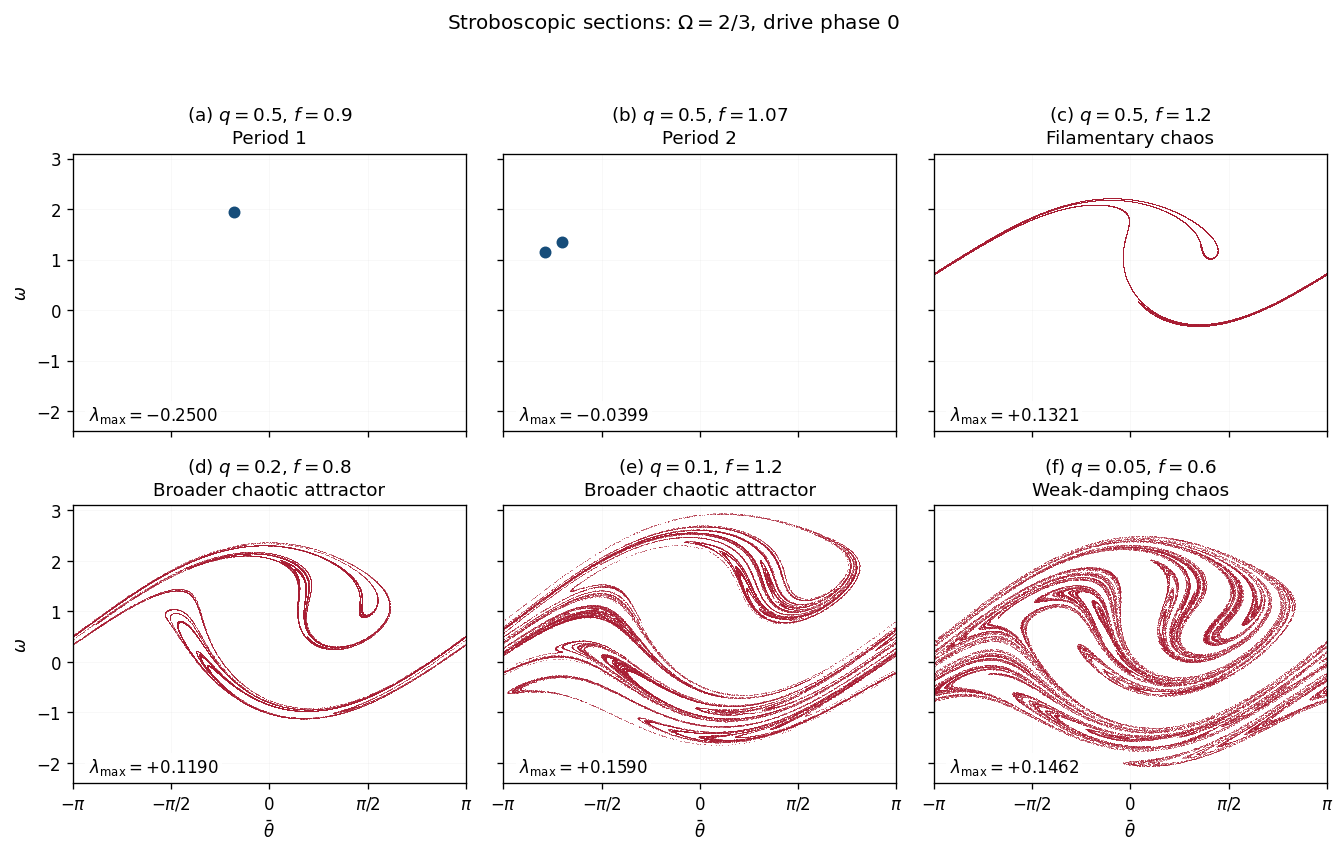

q=0.500, f=0.900: lambda=-0.250002, blocos=[-0.2500129449449639, -0.24998945815007698]
q=0.500, f=1.070: lambda=-0.039931, blocos=[-0.0399306798795872, -0.0399306798795872]
q=0.500, f=1.200: lambda=+0.132102, blocos=[0.13017939929555167, 0.1341276387357811]
q=0.200, f=0.800: lambda=+0.119016, blocos=[0.11764386364871227, 0.12012976401471939]
q=0.100, f=1.200: lambda=+0.159004, blocos=[0.15652842373867282, 0.1606053848540242]
q=0.050, f=0.600: lambda=+0.146182, blocos=[0.14384788862602005, 0.1478076969201284]


In [3]:
fig3, tabela3 = figure3(force=RECALCULAR)
display(fig3)
plt.close(fig3)
for r in tabela3:
    print(f"q={r['q']:.3f}, f={r['f']:.3f}: lambda={r['lambda']:+.6f}, blocos={r['block_range']}")

## Figura 5: cruzamentos e dimensão

**Painéis (a,b):** `q=0.05`, `f=0.12`. A órbita periódica de sela é obtida por um problema de contorno periódico e corrigida por shooting. Seus autovetores são propagados pelos mapas direto/inverso; o traçado é refinado adaptativamente. Interseções de polilinhas fornecem somente palpites. Cada cruzamento é resolvido novamente por integração direta e equações variacionais. A validação aumenta as pernas locais de 2 para 3 e 4 períodos e aperta a tolerância do integrador.

Para conservar sementes minúsculas com precisão, integramos o deslocamento da órbita periódica e usamos a identidade
$\sin(\theta_p+d)-\sin\theta_p=2\cos(\theta_p+d/2)\sin(d/2)$.

**Painéis (c–f):** `q=0.5`, `f=1.2`, o mesmo atrator do manuscrito anterior. As coordenadas de contagem são $u=(\bar\theta+\pi)/(2\pi)$ e $v=\omega/4$. A direção angular é periódica também na contagem de caixas, evitando um artefato da costura do cilindro. São usados 16 deslocamentos de grade; a faixa principal é $\delta=2^{-j}$, `j=6,...,10`.

$D_0$ usa o número de caixas ocupadas. $D_1$ usa a entropia $-\sum p_i\ln p_i$. $D_{\rm KY}=1+\lambda_+/(q+\lambda_+)$ usa o expoente positivo e a contração exata. São quantidades diferentes: não é correto exigir igualdade de $D_0$ com $D_{\rm KY}$. As faixas desenhadas medem a variação entre grades, **não** são intervalos estatísticos de confiança.

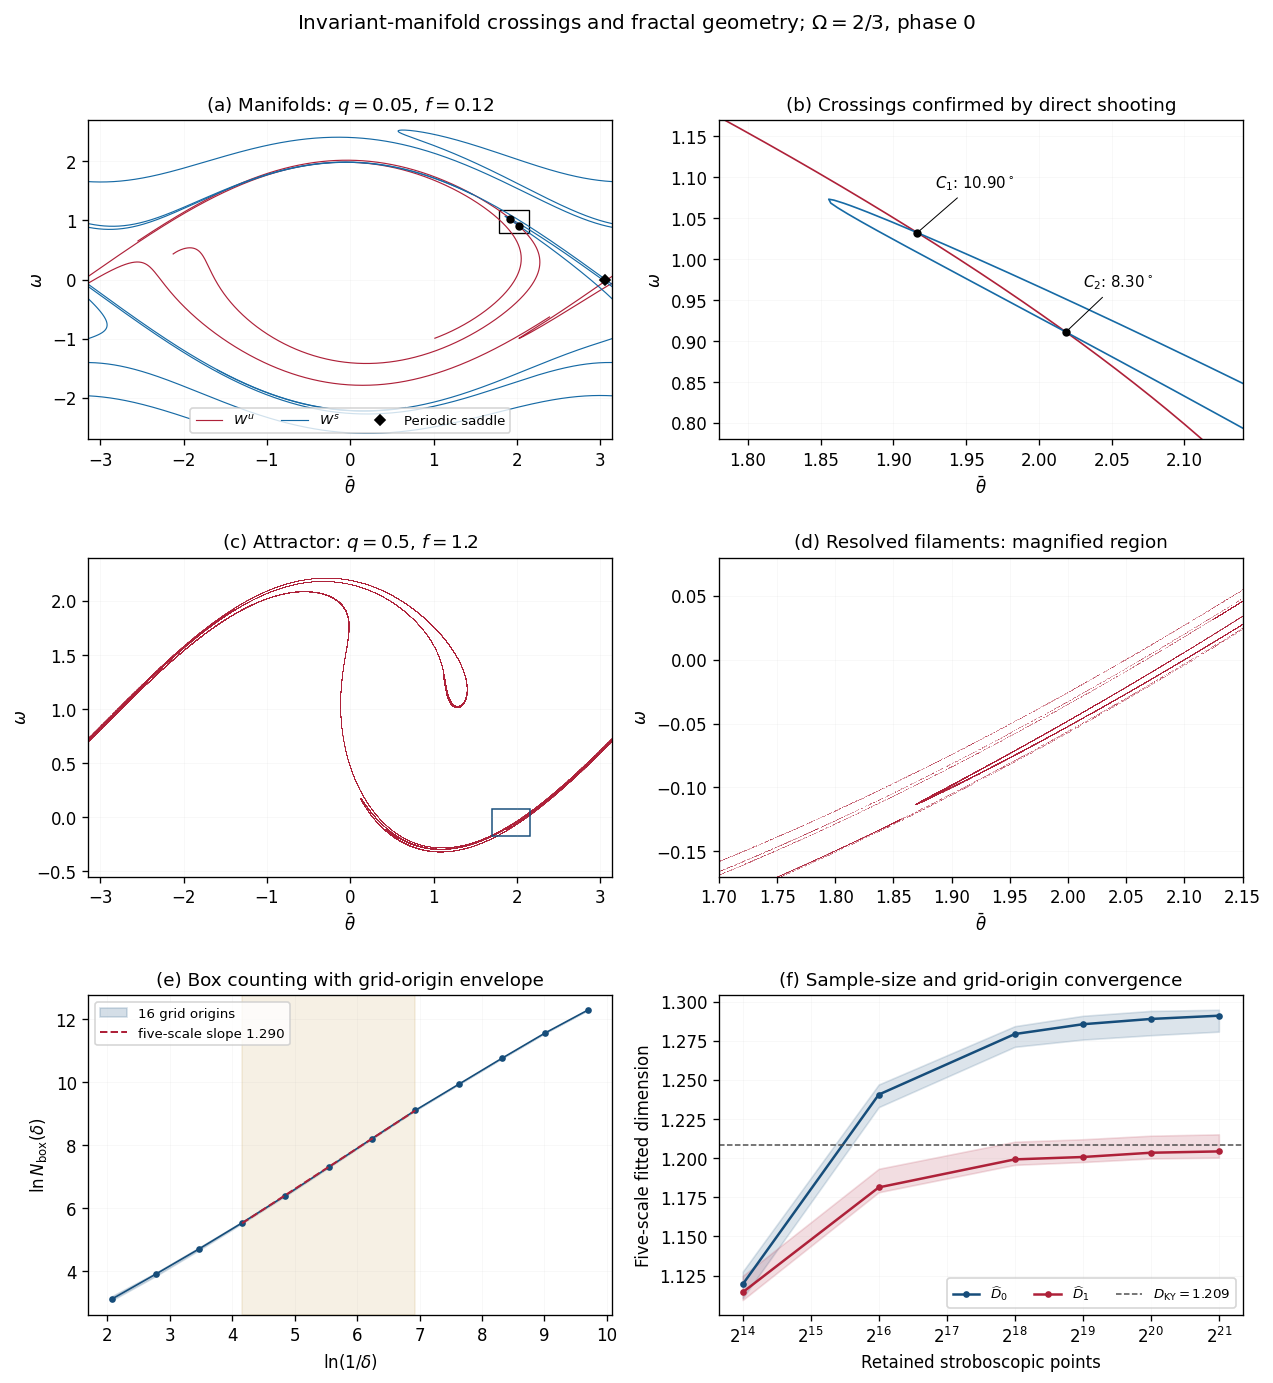

{
  "N": 2097152,
  "lambda": 0.1317414406062405,
  "KY": 1.2085369617035364,
  "fit_levels": [
    6,
    7,
    8,
    9,
    10
  ],
  "D0_median": 1.2909832943474813,
  "D0_grid_range": [
    1.2807933333330084,
    1.294783917485565
  ],
  "D1_median": 1.204308960633984,
  "D1_grid_range": [
    1.2003335304945018,
    1.215204047412797
  ]
}


In [4]:
fig5, tabela5 = figure5(force=RECALCULAR, n=N_FRACTAL)
display(fig5)
plt.close(fig5)
print(json.dumps(tabela5, indent=2))

## Valores e controles dos cruzamentos

Os ângulos são medidos no plano adimensional `(theta, omega)`; o fato de serem diferentes de zero é a evidência numérica de transversalidade. Não se trata de uma prova matemática certificada por aritmética intervalar.

In [5]:
curvas, cruzamentos = compute_manifolds()
for i, item in enumerate(cruzamentos,1):
    print(f"Cruzamento C{i}")
    for r in item["length_checks"] + item["tight_checks"]:
        print("perna:",r["length"],"ponto:",r["point"],"ângulo:",r["angle_deg"],"resíduo:",r["residual"],"rtol:",r["rtol"])

Cruzamento C1
perna: 2 ponto: [1.9163977628672235, 1.0322926314135312] ângulo: 10.902503587091493 resíduo: 2.8033955782700967e-14 rtol: 2e-12
perna: 3 ponto: [1.916397762867195, 1.032292631413558] ângulo: 10.902503587081469 resíduo: 1.055896225427237e-13 rtol: 2e-12
perna: 4 ponto: [1.9163977628669269, 1.0322926314137544] ângulo: 10.902503587095394 resíduo: 7.170768853795847e-14 rtol: 2e-12
perna: 3 ponto: [1.9163977628669322, 1.0322926314137129] ângulo: 10.902503587126134 resíduo: 3.0847422370805075e-15 rtol: 2e-13
Cruzamento C2
perna: 2 ponto: [2.0184937115500077, 0.9109710777363291] ângulo: 8.300343764129138 resíduo: 1.4335640612184642e-14 rtol: 2e-12
perna: 3 ponto: [2.018493711549864, 0.9109710777364682] ângulo: 8.300343764123014 resíduo: 2.57459259216599e-14 rtol: 2e-12
perna: 4 ponto: [2.0184937115504162, 0.910971077735945] ângulo: 8.300343764128169 resíduo: 9.485749680535095e-15 rtol: 2e-12
perna: 3 ponto: [2.0184937115500716, 0.9109710777362122] ângulo: 8.300343764163111 resíd

## Controle da janela e do passo de integração

O gráfico adicional exibe todas as janelas vizinhas de quatro escalas, inclusive as ruins. À direita, as integrações com 480 e 960 passos são comparadas usando o mesmo número de pontos. Não há uma dimensão exata independente de resolução em uma amostra finita. A janela principal de cinco escalas foi escolhida após examinar o patamar intermediário; essa escolha está declarada, não foi um protocolo cego.

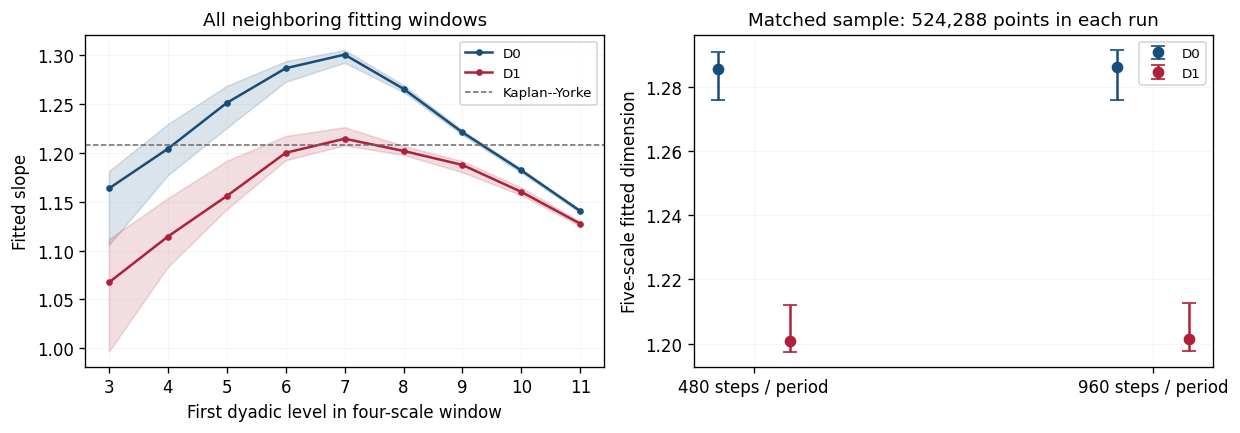

480 steps D0 mediana: 1.285530941960604 D1 mediana: 1.200733482630561
960 steps D0 mediana: 1.2862660191526711 D1 mediana: 1.2015231865106493


In [6]:
fig_controle, controle = convergence_figure()
display(fig_controle)
plt.close(fig_controle)
for r in controle:
    print(r["label"],"D0 mediana:",float(np.median(r["D0"])),"D1 mediana:",float(np.median(r["D1"])))

## Alternativa: somente a amplitude varia

A figura principal usa menor amortecimento para mostrar conjuntos mais preenchidos. A alternativa abaixo mantém `q=0.5` em todos os seis painéis. Ela mostra períodos 1, 2 e 3 e regiões caóticas; não se deve interpretar o período 3 como continuação de uma cascata 1→2→4.

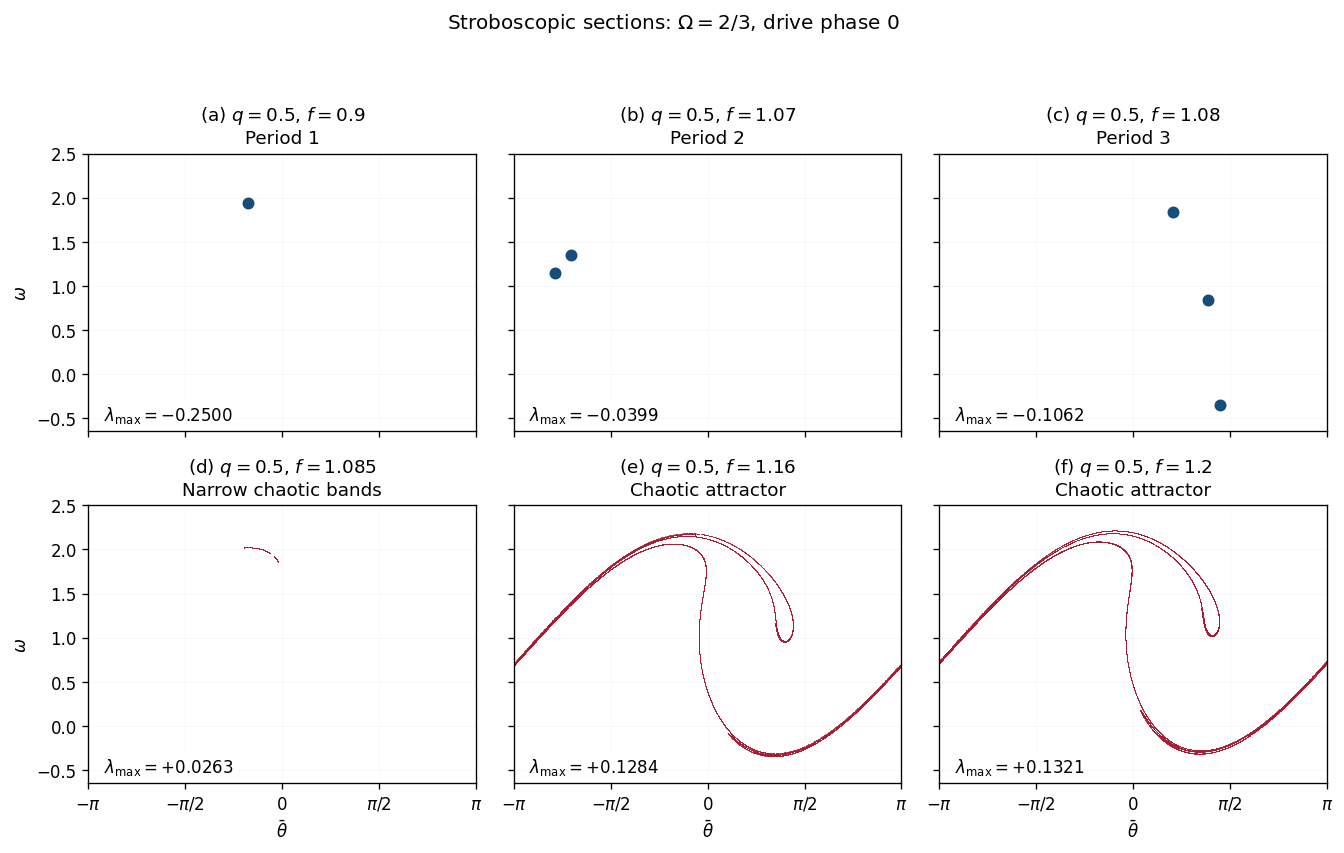

In [7]:
fig_alt, _ = figure3(fixed_damping=True, force=RECALCULAR)
display(fig_alt)
plt.close(fig_alt)

## Uso posterior no artigo

As figuras são gravadas em PNG e PDF vetorial. Os parâmetros dos dois regimes presentes na figura 5 devem permanecer distintos na legenda: os cruzamentos fracos não foram calculados para o mesmo par `(q,f)` da dimensão do atrator. O artigo de referência [Rafat, Wheatland e Bedding, arXiv:0812.0393](https://arxiv.org/abs/0812.0393) inspirou a comparação visual; trata de outro sistema, conservativo, no qual várias condições iniciais podem desenhar curvas invariantes.